# Other things we tried

*Ahmed. Uses the clean table and folds from `02_data-analysis`.*

The main notebooks show the final models. This one is the personal trials part: ideas we tried around them, one after another. Each trial has a short **Why**, **What we did**, the result (a table, a figure and a note with the numbers) and a **Decision**. All of them use the tuned gradient boosting from `outputs/ahmed_hgb_params.json`, and trial 4 also the MLP settings from `../04_neural-networks/outputs/ahmed_mlp_params.json`. Every number uses all 10 plausible values. Every model score uses the 5 school folds (except the random split that trial 1 tests) and is combined with the same Rubin step as the other notebooks.

| Reads | Writes |
|---|---|
| `../data/clean/pisa6_clean.parquet` | `outputs/ahmed_trials.csv` |
| `../data/clean/columns.json` | `outputs/figures/ahmed_trial_0_ceiling.png` |
| `../data/clean/folds.csv` | `outputs/figures/ahmed_trial_1_random_split.png` |
| `outputs/ahmed_hgb_params.json` | `outputs/figures/ahmed_trial_2_leave_one_out.png` |
| `outputs/ahmed_hgb_results.csv` | `outputs/figures/ahmed_trial_3_own_model.png` |
| `outputs/ahmed_hgb_by_system.csv` | `outputs/figures/ahmed_trial_4_ensemble.png` |
| `../04_neural-networks/outputs/ahmed_mlp_params.json` | |
| `../04_neural-networks/outputs/ahmed_mlp_results.csv` | |

# 1) Setup and data

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, root_mean_squared_error, r2_score

DATA = Path("../data")
OUT = Path("outputs")
FIGS = OUT / "figures"
NN = Path("../04_neural-networks/outputs")
df = pd.read_parquet(DATA / "clean/pisa6_clean.parquet")
roles = json.loads((DATA / "clean/columns.json").read_text(encoding="utf-8"))
folds = pd.read_csv(DATA / "clean/folds.csv")
df["fold"] = df["CNTSCHID"].map(folds.set_index("CNTSCHID")["fold"])
GROUPS = roles["feature_groups"]
FEATURES = [c for cols in GROUPS.values() for c in cols]
INPUTS = FEATURES + [f"{c}_missing" for c in FEATURES]
CUTOFF = roles["targets"]["level2_cutoff"]
PVS = range(1, 11)
SYSTEMS = ["ARE", "SAU", "QAT", "JOR", "MAR", "PSE"]
TASKS = ["classification", "regression"]
w = df["SENWT"] / df["SENWT"].mean()
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

best = json.loads((OUT / "ahmed_hgb_params.json").read_text(encoding="utf-8"))
mlp_best = json.loads((NN / "ahmed_mlp_params.json").read_text(encoding="utf-8"))
saved = pd.read_csv(OUT / "ahmed_hgb_results.csv")
saved_by_system = pd.read_csv(OUT / "ahmed_hgb_by_system.csv")

# no reading or science scores, no plausible values among the inputs
assert not any(c.startswith("PV") or "READ" in c or "SCIE" in c for c in INPUTS)
X = df[FEATURES]
X_mlp = df[INPUTS]
print("gradient boosting:", best)
print("MLP:", mlp_best)
df["CNT"].value_counts()[SYSTEMS].rename("students")

gradient boosting: {'classification': {'learning_rate': 0.05, 'max_leaf_nodes': 31}, 'regression': {'learning_rate': 0.05, 'max_leaf_nodes': 63}}
MLP: {'classification': {'hidden_layer_sizes': [128, 64], 'alpha': 0.01}, 'regression': {'hidden_layer_sizes': [128, 64], 'alpha': 1.0}}


CNT
ARE    24600
SAU     6928
QAT     7676
JOR     7799
MAR     6867
PSE     7905
Name: students, dtype: int64

Gradient boosting gets the 17 raw predictors with blanks left in, the MLP the 17 predictors and their `_missing` flags, exactly as in their own notebooks. ARE has by far the most students, which matters for trials 2 and 3.

# 1.1) The loop
The same loop as `ahmed_ablations.ipynb`, cut into two steps so the trials can reuse them. `run` fits a model on every PV and fold and keeps the test predictions, and `fold_scores` scores them on each test fold: pooled with `SENWT` and inside each system with `W_FSTUWT`. The fold labels are an argument, so trial 1 can pass random folds instead. We keep two metrics per task: ROC-AUC and balanced accuracy at 0.5 for below Level 2, RMSE and R² for the maths score.

`gain` is the paired comparison from the ablations notebook: the new score minus the reference one on each system, PV and fold (for RMSE the other way round, so positive always means the new one is better), then the Rubin step.

In [2]:
def score(task, y, p, sw):
    if task == "classification":
        return {"roc_auc": roc_auc_score(y, p, sample_weight=sw),
                "balanced_acc": balanced_accuracy_score(y, p > 0.5, sample_weight=sw)}
    return {"rmse": root_mean_squared_error(y, p, sample_weight=sw),
            "r2": r2_score(y, p, sample_weight=sw)}


def target(task, pv):
    return df[f"BELOW_L2_PV{pv}"] if task == "classification" else df[f"PV{pv}MATH"]


def fit_predict(task, y, train, test):
    if task == "classification":
        model = HistGradientBoostingClassifier(**best[task], random_state=0)
        model.fit(X[train], y[train], sample_weight=w[train] * compute_sample_weight("balanced", y[train]))
        return model.predict_proba(X[test])[:, 1]
    model = HistGradientBoostingRegressor(**best[task], random_state=0)
    model.fit(X[train], y[train], sample_weight=w[train])
    return model.predict(X[test])


def run(task, pvs, fold=df["fold"], fit=fit_predict):
    preds = {}
    for pv in pvs:
        y = target(task, pv)
        preds[pv] = pd.Series(np.nan, index=df.index)
        for k in range(5):
            preds[pv][fold == k] = fit(task, y, fold != k, fold == k)
    return preds


def fold_scores(task, preds, fold=df["fold"]):
    rows = []
    for pv, p in preds.items():
        y = target(task, pv)
        for k in range(5):
            test = fold == k
            rows.append({"system": "pooled", "pv": pv, "fold": k, **score(task, y[test], p[test], w[test])})
            for cnt in SYSTEMS:
                m = test & (df["CNT"] == cnt)
                rows.append({"system": cnt, "pv": pv, "fold": k,
                             **score(task, y[m], p[m], df.loc[m, "W_FSTUWT"])})
    return pd.DataFrame(rows)


def rubin(res):
    per_pv = res.groupby("pv").mean().drop(columns="fold")
    within = res.groupby("pv").var().drop(columns="fold").mean() / 5
    between = per_pv.var()
    return pd.DataFrame({"score": per_pv.mean(), "se": np.sqrt(within + 1.1 * between)})


def combine(res):
    out = [rubin(d.drop(columns="system")).rename_axis("metric").reset_index().assign(system=cnt)
           for cnt, d in res.groupby("system", sort=False)]
    return pd.concat(out, ignore_index=True)


def gain(new, old):
    assert (new[["system", "pv", "fold"]].values == old[["system", "pv", "fold"]].values).all()
    diff = new.copy()
    for metric in diff.columns.drop(["system", "pv", "fold"]):
        diff[metric] = (-1 if metric == "rmse" else 1) * (new[metric] - old[metric])
    return combine(diff)

Every trial adds its rows to one long table with `keep`, which is saved in the summary. `show` prints one trial from it, and `bars` draws the per-system bars used in most figures, with 95% intervals (1.96 se).

In [3]:
trials = []


def keep(trial, variant, task, table):
    trials.append(table.assign(trial=trial, variant=variant, task=task)
                  [["trial", "variant", "task", "system", "metric", "score", "se"]])


def show(trial, systems):
    d = pd.concat(trials)
    d = d[(d["trial"] == trial) & d["system"].isin(systems)]
    table = d.set_index(["task", "metric", "system", "variant"])[["score", "se"]].unstack("variant")
    return table.swaplevel(axis=1)[d["variant"].unique()].round(4)


NAMES = {"pooled": "All six", **{cnt: cnt for cnt in SYSTEMS}}


def bars(ax, tables, labels, colors, metric, systems):
    x = np.arange(len(systems))
    width = 0.8 / len(tables)
    for i, (t, label, color) in enumerate(zip(tables, labels, colors)):
        d = t[t["metric"] == metric].set_index("system").loc[systems]
        ax.bar(x + (i - (len(tables) - 1) / 2) * width, d["score"], width, yerr=1.96 * d["se"],
               color=color, capsize=2, label=label)
    ax.set_xticks(x, [NAMES[s] for s in systems])

# 1.2) The main model again
Most trials are compared with the main model on the same PV and fold, and the saved results only have the combined scores. So we rerun it once here and keep its test predictions for trials 1, 2, 3 and 4. With the same settings and `random_state=0` it should match `outputs/ahmed_hgb_results.csv` and `outputs/ahmed_hgb_by_system.csv`.

In [4]:
base = {task: run(task, PVS) for task in TASKS}
base_scores = {task: fold_scores(task, base[task]) for task in TASKS}

check = pd.concat([combine(base_scores[task]).assign(task=task) for task in TASKS])
ref = pd.concat([saved.assign(system="pooled"), saved_by_system])
check = check.merge(ref[["task", "system", "metric", "score"]], on=["task", "system", "metric"],
                    suffixes=("", "_saved"))
print("largest gap to the saved scores, all systems and metrics:", (check["score"] - check["score_saved"]).abs().max())
check[check["system"] == "pooled"].round(4)

largest gap to the saved scores, all systems and metrics: 8.326672684688674e-17


,metric,score,se,system,task,score_saved
0,roc_auc,0.8186,0.0036,pooled,classification,0.8186
1,balanced_acc,0.7350,0.0035,pooled,classification,0.7350
14,rmse,60.7497,0.3279,pooled,regression,60.7497
15,r2,0.4285,0.0117,pooled,regression,0.4285


> **Note:** the rerun matches the saved results (largest gap 8e-17 over all systems and metrics, which is just rounding), so every trial below is compared with the model from `ahmed_gradient_boosting.ipynb`.

# 2) Trial 0: how good could it get?
**Why.** A student's maths score is not one number but 10 plausible values, drawn from what the test says about them. Part of the spread between them is noise that no questionnaire answer can predict. Before judging our R² of 0.428 we want to know how high it could go.

**What we did.** Three things that need no real model. (1) The share of the spread of the scores that sits between the 10 PVs of the same student. (2) An oracle that predicts each PV from the mean of the other nine, with a one-predictor `LinearRegression` on the same school folds. It already knows what the test says about the student, so it is about the best any model could do. For below Level 2 it flags a student when its predicted score is under the Level 2 cut-off. We put our gradient boosting next to it, from `outputs/ahmed_hgb_results.csv` and `outputs/ahmed_hgb_by_system.csv`. (3) ESCS alone in each system: the R² of a straight line on ESCS, the OECD's measure of how strongly maths is tied to socio-economic status. It is in-sample like the OECD figure (with one predictor there is little to overfit).

This trial always uses all 10 PVs (the oracle needs the other nine, and nothing here is slow), so its numbers do not change with `PVS`.

In [5]:
pv_math = df[[f"PV{pv}MATH" for pv in range(1, 11)]]

rows = []
for system in SYSTEMS + ["pooled"]:
    m = df["CNT"].isin(SYSTEMS) if system == "pooled" else df["CNT"] == system
    sw = (w if system == "pooled" else df["W_FSTUWT"])[m]
    d = pv_math[m]
    grand = np.average(d.mean(axis=1), weights=sw)
    total = np.average(((d - grand) ** 2).mean(axis=1), weights=sw)
    noise = np.average(d.var(axis=1), weights=sw)
    e = df.loc[m, "ESCS"].notna()
    covs = [np.cov(df.loc[m, "ESCS"][e], d[col][e], aweights=sw[e]) for col in d]
    rows.append({"system": system, "sd_score": np.sqrt(total), "sd_noise": np.sqrt(noise),
                 "noise_share": noise / total,
                 "escs_r2": np.mean([c[0, 1] ** 2 / (c[0, 0] * c[1, 1]) for c in covs])})
spread = pd.DataFrame(rows).set_index("system")
spread.round(3)

,sd_score,sd_noise,noise_share,escs_r2
system,,,,
ARE,101.356,31.480,0.096,0.058
SAU,65.582,27.188,0.172,0.064
QAT,88.759,27.312,0.095,0.117
JOR,61.728,26.813,0.189,0.052
MAR,62.699,25.249,0.162,0.085
PSE,65.942,27.128,0.169,0.074
pooled,80.450,27.594,0.118,0.132


`sd_score` is the spread of all 10 PVs together, `sd_noise` the typical spread between the PVs of one student (the between-PV variance with `ddof=1`, the same one `rubin` uses), and `noise_share` the share of the variance that is between PVs (`sd_noise²` over `sd_score²`). `escs_r2` is weighted and averaged over the 10 PVs, as the OECD does.

> **Note:** pooled, 0.118 of the variance of the maths scores is between the PVs of the same student: one student's 10 PVs spread by about 28 points, against 80 for all students. That noise is about the same size in every system (25 to 31 points), so the systems with a narrow spread of scores lose more of their variance to it: 0.162 to 0.189 in SAU, JOR, MAR and PSE against 0.095 and 0.096 in QAT and ARE. The PISA 2022 Technical Report (OECD, 2023) gives a maths reliability of 0.81 (JOR) to 0.91 (QAT), so a PV share of about 0.09 to 0.19, and ours is within 0.01 of it in every system. ESCS alone explains 0.052 (JOR) to 0.117 (QAT) of the variance inside a system. The OECD (2023, PISA 2022 Results Volume I) reports 5.8% for ARE, 6.4% SAU, 11.7% QAT, 5.2% JOR, 8.5% MAR and 7.4% PSE. Ours are the same in every system, which checks our weights and PV handling. All six are below the OECD average of 15.5%, and pooled it is 0.132, higher than inside any one system, probably because the differences between systems in ESCS and in maths go the same way.

In [6]:
oracle = {"classification": {}, "regression": {}}
for pv in range(1, 11):
    y = df[f"PV{pv}MATH"]
    others = pv_math.drop(columns=f"PV{pv}MATH").mean(axis=1).to_frame("other nine")
    pred = pd.Series(np.nan, index=df.index)
    for k in range(5):
        train, test = df["fold"] != k, df["fold"] == k
        pred[test] = LinearRegression().fit(others[train], y[train], sample_weight=w[train]).predict(others[test])
    oracle["regression"][pv] = pred
    # not a probability: above 0.5 exactly when the predicted score is under the cut-off,
    # and ROC-AUC only uses the order
    oracle["classification"][pv] = 0.5 + CUTOFF - pred

ceiling = {task: combine(fold_scores(task, oracle[task])) for task in TASKS}
gb_all = pd.concat([saved.assign(system="pooled"), saved_by_system])
gb = {task: gb_all[gb_all["task"] == task] for task in TASKS}


def pick(table, metric):
    return table[table["metric"] == metric].set_index("system")["score"]


share = pd.DataFrame({"oracle_r2": pick(ceiling["regression"], "r2"),
                      "hgb_r2": pick(gb["regression"], "r2"),
                      "oracle_roc_auc": pick(ceiling["classification"], "roc_auc"),
                      "hgb_roc_auc": pick(gb["classification"], "roc_auc")}).loc[SYSTEMS + ["pooled"]]
share["r2_share"] = share["hgb_r2"] / share["oracle_r2"]
# ROC-AUC counts from 0.5, which is chance
share["roc_auc_share"] = (share["hgb_roc_auc"] - 0.5) / (share["oracle_roc_auc"] - 0.5)
share.round(3)

,oracle_r2,hgb_r2,oracle_roc_auc,hgb_roc_auc,r2_share,roc_auc_share
system,,,,,,
ARE,0.892,0.460,0.973,0.824,0.516,0.685
SAU,0.809,0.203,0.954,0.726,0.251,0.499
QAT,0.893,0.429,0.972,0.814,0.481,0.664
JOR,0.790,0.222,0.960,0.771,0.281,0.590
MAR,0.818,0.296,0.970,0.809,0.362,0.658
PSE,0.811,0.292,0.965,0.783,0.360,0.609
pooled,0.869,0.428,0.970,0.819,0.493,0.678


In [7]:
pd.concat(ceiling.values()).pivot_table(index="system", columns="metric", values=["score", "se"]).loc[SYSTEMS + ["pooled"]].round(3)

score                                  se                      
metric balanced_acc     r2    rmse roc_auc balanced_acc     r2   rmse roc_auc
system                                                                       
ARE           0.909  0.892  33.168   0.973        0.003  0.004  0.430   0.002
SAU           0.863  0.809  28.626   0.954        0.006  0.007  0.400   0.003
QAT           0.903  0.893  28.735   0.972        0.006  0.007  0.446   0.003
JOR           0.834  0.790  28.230   0.960        0.010  0.007  0.359   0.003
MAR           0.864  0.818  26.591   0.970        0.011  0.010  0.224   0.004
PSE           0.855  0.811  28.571   0.965        0.008  0.006  0.358   0.003
pooled        0.889  0.869  29.064   0.970        0.003  0.003  0.151   0.001

> **Note:** the oracle reaches R² 0.869 and ROC-AUC 0.970 pooled (se 0.003 and 0.001), with an RMSE of 29.1 points. That is what PV noise alone predicts: one PV differs from the mean of the other nine by about 27.6 × sqrt(1 + 1/9) = 29.1 points. So about 0.13 of the variance is out of reach even for the oracle, and our gradient boosting (R² 0.428) gets 0.49 of what the oracle gets. For ROC-AUC it gets 0.68 of the way from chance (0.5) to the oracle. The oracle is lowest in JOR (R² 0.790). SAU, PSE and MAR come next (0.809 to 0.818, within the noise of each other), and JOR is probably below all three: the smallest gap, to SAU (0.019), is about 2 × sqrt(0.007² + 0.007²) = 0.020. These are the four systems where PV noise is the biggest share. Our model also gets a much smaller share of the oracle in JOR and SAU (0.28 and 0.25 of R²) than in ARE and QAT (0.52 and 0.48). So those systems are not only noisier: the 17 predictors also carry less about maths there.

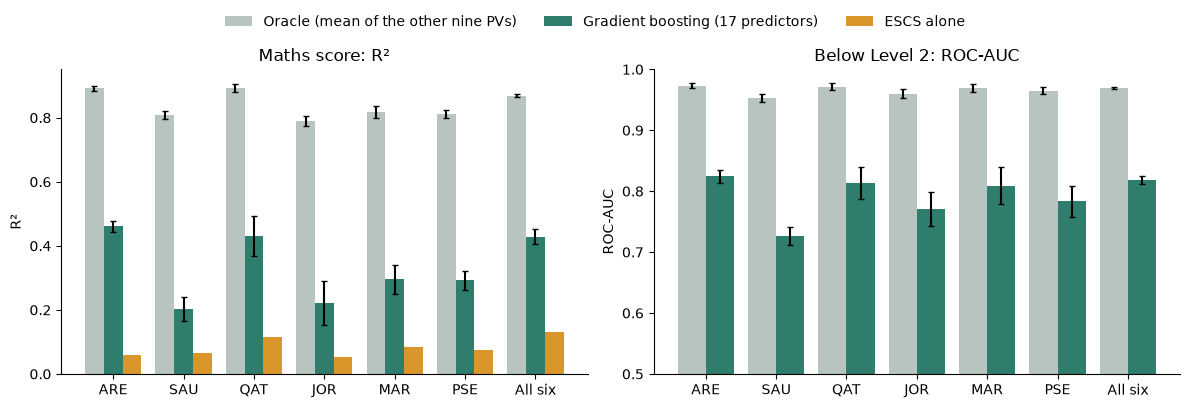

In [8]:
def as_table(s, metric):
    return s.rename("score").rename_axis("system").reset_index().assign(metric=metric, se=np.nan)


escs_table = as_table(spread["escs_r2"], "r2")
for task in TASKS:
    keep("ceiling", "oracle", task, ceiling[task])
    keep("ceiling", "gradient boosting", task, gb[task])
keep("ceiling", "plausible-value noise", "regression", as_table(spread["noise_share"], "noise_share"))
keep("ceiling", "ESCS alone", "regression", escs_table)
keep("ceiling", "gradient boosting share of oracle", "regression", as_table(share["r2_share"], "r2_share_of_oracle"))
keep("ceiling", "gradient boosting share of oracle", "classification", as_table(share["roc_auc_share"], "roc_auc_share_of_oracle"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
order = SYSTEMS + ["pooled"]
bars(axes[0], [ceiling["regression"], gb["regression"], escs_table],
     ["Oracle (mean of the other nine PVs)", "Gradient boosting (17 predictors)", "ESCS alone"],
     ["#B8C4C0", "#2F7D6D", "#D9962B"], "r2", order)
axes[0].set_title("Maths score: R²")
axes[0].set_ylabel("R²")
bars(axes[1], [ceiling["classification"], gb["classification"]],
     ["Oracle (mean of the other nine PVs)", "Gradient boosting (17 predictors)"],
     ["#B8C4C0", "#2F7D6D"], "roc_auc", order)
axes[1].set_ylim(0.5, 1)
axes[1].set_title("Below Level 2: ROC-AUC")
axes[1].set_ylabel("ROC-AUC")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
fig.savefig(FIGS / "ahmed_trial_0_ceiling.png", bbox_inches="tight", dpi=150)
plt.show()

**Decision.** Nothing to change in the models, but it gives the scale for the report. Our R² of 0.428 is about half of what these PVs allow (0.869), and our ROC-AUC of 0.819 is about two thirds of the way from chance to the oracle (0.970). What is missing is what the 17 questionnaire indices don't carry. So the way up is other predictors rather than another model, which is also where the tree-count check in `ahmed_gradient_boosting.ipynb` and the MLP comparison point.

# 3) Trial 1: random split vs school split
**Why.** Almost every published PISA study splits students at random. Students in the same school are alike (same area, same teachers, often a similar background), so with a random split the model has already seen classmates of every test student. Mandalunes (2026) found that a random split gave a higher R² than a school-grouped split in 604 of 606 cases. Our folds keep whole schools together, so our numbers are for schools the model has never seen.

**What we did.** The same tuned gradient boosting on 5 folds of students drawn at random (`KFold(5, shuffle=True, random_state=0)`), against the school folds from 1.2. The random folds are not the same rows as the school folds, so here the gap is only paired on the PV, and the fold-to-fold noise of both splits counts in its se.

In [9]:
random_fold = pd.Series(0, index=df.index)
for k, (_, test) in enumerate(KFold(5, shuffle=True, random_state=0).split(df)):
    random_fold.iloc[test] = k

rand_scores = {task: fold_scores(task, run(task, PVS, random_fold), random_fold) for task in TASKS}
for task in TASKS:
    keep("random split", "school folds", task, combine(base_scores[task]))
    keep("random split", "random folds", task, combine(rand_scores[task]))
    keep("random split", "gain of random folds", task, gain(rand_scores[task], base_scores[task]))
show("random split", ["pooled"])

variant                            school folds         random folds          \
                                          score      se        score      se   
task           metric       system                                             
classification balanced_acc pooled       0.7350  0.0035       0.7404  0.0035   
               roc_auc      pooled       0.8186  0.0036       0.8251  0.0031   
regression     r2           pooled       0.4285  0.0117       0.4549  0.0042   
               rmse         pooled      60.7497  0.3279      59.3916  0.3817   

variant                            gain of random folds          
                                                  score      se  
task           metric       system                               
classification balanced_acc pooled               0.0054  0.0034  
               roc_auc      pooled               0.0065  0.0030  
regression     r2           pooled               0.0264  0.0100  
               rmse         pooled               1.3581  0.2384

> **Note:** `gain of random folds` is how much better the same model looks with a random split (for RMSE, how many points lower). Pooled, the ROC-AUC goes from 0.819 to 0.825 (gain 0.0065, se 0.0030) and R² from 0.428 to 0.455 (gain 0.0264, se 0.0100), with the RMSE 1.36 points lower (se 0.24). The R² and RMSE gains are clear (about 2.7 and 5.7 se), and the ROC-AUC gain is about 2 se, so it is probably real but small. Eren and Niksarli (2026) report a ROC-AUC of 0.818 for Turkiye with a random split and similar indices. It is another country, so this is only a rough comparison, but their number belongs next to our random-split one (0.825), not our school-split one.

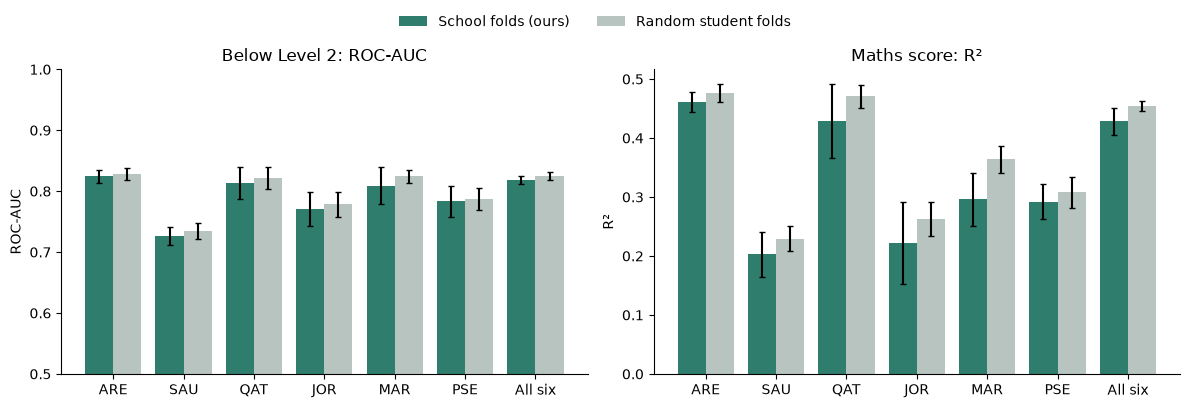

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (task, metric, title) in zip(axes, [("classification", "roc_auc", "Below Level 2: ROC-AUC"),
                                            ("regression", "r2", "Maths score: R²")]):
    bars(ax, [combine(base_scores[task]), combine(rand_scores[task])],
         ["School folds (ours)", "Random student folds"], ["#2F7D6D", "#B8C4C0"], metric, SYSTEMS + ["pooled"])
    ax.set_title(title)
axes[0].set_ylim(0.5, 1)
axes[0].set_ylabel("ROC-AUC")
axes[1].set_ylabel("R²")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
fig.savefig(FIGS / "ahmed_trial_1_random_split.png", bbox_inches="tight", dpi=150)
plt.show()

In [11]:
show("random split", SYSTEMS)["gain of random folds"]

score      se
task           metric       system                
classification balanced_acc ARE     0.0049  0.0068
                            JOR     0.0034  0.0147
                            MAR     0.0190  0.0213
                            PSE     0.0011  0.0148
                            QAT     0.0060  0.0133
                            SAU     0.0055  0.0087
               roc_auc      ARE     0.0035  0.0058
                            JOR     0.0072  0.0163
                            MAR     0.0159  0.0160
                            PSE     0.0043  0.0121
                            QAT     0.0080  0.0130
                            SAU     0.0085  0.0085
regression     r2           ARE     0.0157  0.0065
                            JOR     0.0411  0.0388
                            MAR     0.0679  0.0243
                            PSE     0.0155  0.0173
                            QAT     0.0410  0.0313
                            SAU     0.0267  0.0212
               rmse         ARE     1.0444  0.8691
                            JOR     1.3147  1.0061
                            MAR     2.3739  1.0404
                            PSE     0.4983  1.0379
                            QAT     1.7945  1.1978
                            SAU     0.9828  0.7203

> **Note:** each bar's interval is that score's own, while the table above has the se of the paired gain, which is what tells us whether a gap is clear. Inside the systems the random split looks better in all 6 for ROC-AUC and all 6 for R², but most of these gains are within the noise: none of the ROC-AUC gains is beyond 2 se, and for R² only MAR (2.8 se) and ARE (2.4 se) are. The R² gain is largest in MAR (0.0679, se 0.0243) and smallest in PSE (0.0155, se 0.0173), with ARE about the same (0.0157, se 0.0065). Even the MAR to PSE gap (0.052) is within the noise, under 2 × sqrt(0.0243² + 0.0173²) = 0.060, so the order of the systems is not clear. If the bigger gain in MAR is real, students in the same school are more alike there, so seeing their classmates helps the model more.

**Decision.** We keep the school folds: the team's question is about schools the model has not seen. When the report puts our numbers next to published ones it should say which split they used, and that on our data a random split adds about 0.007 to the ROC-AUC (se 0.003, about 2 se, so probably real) and 0.026 to the R² (se 0.010).

# 4) Trial 2: leave one system out
**Why.** The pooled model has seen other schools from the same system as each test school. Would a model built in other systems work in a new one, for example a seventh country that joins later?

**What we did.** For each system, train on the other five (all their folds) and predict every student of the sixth. We score these predictions on the same test folds as the pooled model, with `W_FSTUWT`, so the comparison with the pooled model's per-system scores from 1.2 (the same as `outputs/ahmed_hgb_by_system.csv`) is paired on the same students, PV and fold. Five whole systems give a bit more training rows than four folds of all six, except when ARE is left out, since it has the most students.

In [12]:
loso_scores = {}
for task in TASKS:
    preds = {}
    for pv in PVS:
        y = target(task, pv)
        preds[pv] = pd.Series(np.nan, index=df.index)
        for cnt in SYSTEMS:
            test = df["CNT"] == cnt
            preds[pv][test] = fit_predict(task, y, ~test, test)
    loso_scores[task] = fold_scores(task, preds)

for task in TASKS:
    keep("leave one system out", "pooled model", task, combine(base_scores[task]).query("system != 'pooled'"))
    keep("leave one system out", "other five systems", task, combine(loso_scores[task]).query("system != 'pooled'"))
    keep("leave one system out", "gain of other five systems", task,
         gain(loso_scores[task], base_scores[task]).query("system != 'pooled'"))
show("leave one system out", SYSTEMS)

variant                            pooled model         other five systems  \
                                          score      se              score   
task           metric       system                                           
classification balanced_acc ARE          0.7238  0.0067             0.6912   
                            JOR          0.6778  0.0124             0.6757   
                            MAR          0.6548  0.0207             0.6312   
                            PSE          0.6618  0.0133             0.6432   
                            QAT          0.7331  0.0118             0.7295   
                            SAU          0.6600  0.0076             0.6529   
               roc_auc      ARE          0.8243  0.0055             0.7987   
                            JOR          0.7714  0.0142             0.7704   
                            MAR          0.8089  0.0154             0.7833   
                            PSE          0.7831  0.0130             0.7796   
                            QAT          0.8135  0.0134             0.8107   
                            SAU          0.7262  0.0074             0.7230   
regression     r2           ARE          0.4604  0.0087             0.3644   
                            JOR          0.2218  0.0355             0.1981   
                            MAR          0.2960  0.0230             0.2508   
                            PSE          0.2923  0.0153             0.2782   
                            QAT          0.4294  0.0319             0.4213   
                            SAU          0.2027  0.0197             0.1797   
               rmse         ARE         74.3723  1.2209            80.7139   
                            JOR         54.2698  0.8780            55.0957   
                            MAR         52.3571  1.0196            54.0197   
                            PSE         55.3418  0.8133            55.8910   
                            QAT         66.3219  0.9675            66.8266   
                            SAU         58.5094  0.9177            59.3401   

variant                                    gain of other five systems          
                                        se                      score      se  
task           metric       system                                             
classification balanced_acc ARE     0.0046                    -0.0326  0.0040  
                            JOR     0.0112                    -0.0021  0.0050  
                            MAR     0.0193                    -0.0236  0.0075  
                            PSE     0.0126                    -0.0186  0.0056  
                            QAT     0.0122                    -0.0036  0.0041  
                            SAU     0.0084                    -0.0071  0.0053  
               roc_auc      ARE     0.0067                    -0.0256  0.0044  
                            JOR     0.0143                    -0.0010  0.0031  
                            MAR     0.0130                    -0.0257  0.0065  
                            PSE     0.0132                    -0.0036  0.0032  
                            QAT     0.0136                    -0.0028  0.0020  
                            SAU     0.0083                    -0.0032  0.0037  
regression     r2           ARE     0.0171                    -0.0961  0.0125  
                            JOR     0.0353                    -0.0237  0.0051  
                            MAR     0.0223                    -0.0452  0.0108  
                            PSE     0.0158                    -0.0141  0.0040  
                            QAT     0.0294                    -0.0081  0.0052  
                            SAU     0.0240                    -0.0230  0.0076  
               rmse         ARE     1.6611                    -6.3415  0.8086  
                            JOR     0.8372                    -0.8260  0.1770  
                            MAR     1.0510           

> **Note:** trained on the other five systems, the R² is lower in all 6 systems, most in ARE (gain -0.0961, se 0.0125), then MAR (-0.0452, se 0.0108), though MAR's drop is not clearly bigger than JOR's or SAU's. The drop is clear in 5 of them. Only QAT's (-0.0081, se 0.0052) is within the noise. Leaving ARE out still trains on about 37,000 students from the other five systems, against about 49,000 for the pooled model, and the learning curve in `ahmed_gradient_boosting.ipynb` shows that a somewhat smaller training set costs little. So most of ARE's drop is probably what the other five systems don't know about ARE. The ROC-AUC is lower in all 6 too, by up to 0.0257 in MAR (0.0256 in ARE), but only those two drops are clear. In the other four it is 0.0036 or less and within the noise. Balanced accuracy at 0.5 drops by up to 0.0326 (ARE), since the class weights and so the cut-off now come from the other five systems. As before, a gap counts as clear only beyond about 2 se. The bars in the figure below show each score with its own interval. Whether a drop is clear comes from the paired gains in the table, which are usually much tighter.

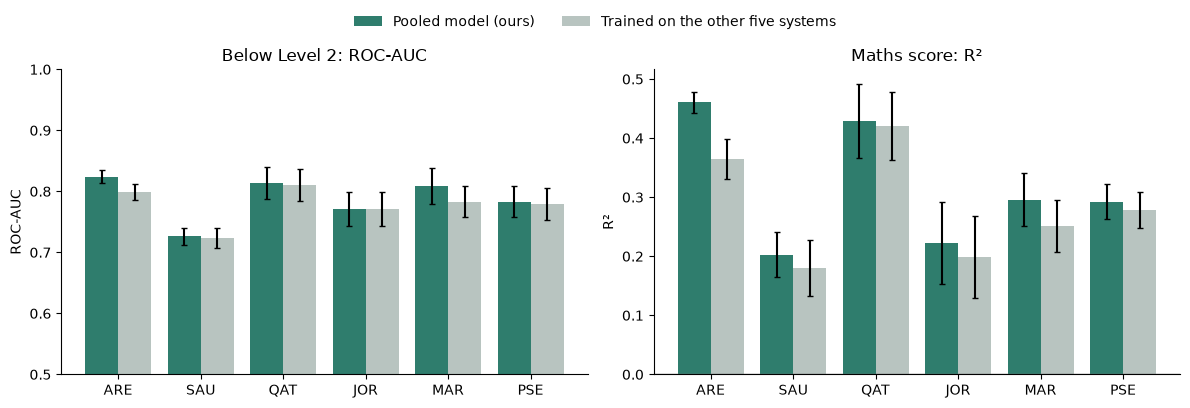

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (task, metric, title) in zip(axes, [("classification", "roc_auc", "Below Level 2: ROC-AUC"),
                                            ("regression", "r2", "Maths score: R²")]):
    bars(ax, [combine(base_scores[task]), combine(loso_scores[task])],
         ["Pooled model (ours)", "Trained on the other five systems"], ["#2F7D6D", "#B8C4C0"], metric, SYSTEMS)
    ax.set_title(title)
    ax.axhline(0, color="grey", lw=1)
axes[0].set_ylim(0.5, 1)
axes[0].set_ylabel("ROC-AUC")
axes[1].set_ylabel("R²")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
fig.savefig(FIGS / "ahmed_trial_2_leave_one_out.png", bbox_inches="tight", dpi=150)
plt.show()

**Decision.** We keep the pooled model trained on all six systems. For the report: a model built elsewhere loses up to 0.096 of R² in a new system (ARE) and its 0.5 cut-off moves, so it should be checked on some of that system's own students before it is used there.

# 5) Trial 3: one model per system
**Why.** The systems differ a lot: in the share below Level 2, in the spread of scores and in how well the model does. A separate model for each system, like routing each group of students to its own model, could fit each one better. But each model only learns from one system, and five of the six have fewer than 8,000 students (section 1), so about 6,000 training rows per fold.

**What we did.** Same settings and the same school folds, but each model is trained only on one system's training rows and scored on that system's test rows (`W_FSTUWT`). It is paired with the pooled model's per-system scores from 1.2. Keeping the same settings has two side effects. The balanced class weights are now worked out inside each system, which moves the 0.5 cut-off as in `ahmed_country_immigrant.ipynb`. And with 10,000 training rows or fewer scikit-learn turns early stopping off by itself, so every system except ARE uses all 100 trees. The `All six` row puts the six models' predictions together and scores them pooled with `SENWT`.

In [14]:
own_scores = {}
for task in TASKS:
    preds = {}
    for pv in PVS:
        y = target(task, pv)
        preds[pv] = pd.Series(np.nan, index=df.index)
        for cnt in SYSTEMS:
            for k in range(5):
                train = (df["CNT"] == cnt) & (df["fold"] != k)
                test = (df["CNT"] == cnt) & (df["fold"] == k)
                preds[pv][test] = fit_predict(task, y, train, test)
    own_scores[task] = fold_scores(task, preds)

for task in TASKS:
    keep("one model per system", "pooled model", task, combine(base_scores[task]))
    keep("one model per system", "own model", task, combine(own_scores[task]))
    keep("one model per system", "gain of own model", task, gain(own_scores[task], base_scores[task]))
show("one model per system", SYSTEMS + ["pooled"])

variant                            pooled model         own model          \
                                          score      se     score      se   
task           metric       system                                          
classification balanced_acc ARE          0.7238  0.0067    0.7445  0.0048   
                            JOR          0.6778  0.0124    0.6807  0.0140   
                            MAR          0.6548  0.0207    0.7120  0.0165   
                            PSE          0.6618  0.0133    0.6946  0.0102   
                            QAT          0.7331  0.0118    0.7335  0.0146   
                            SAU          0.6600  0.0076    0.6511  0.0080   
                            pooled       0.7350  0.0035    0.7169  0.0045   
               roc_auc      ARE          0.8243  0.0055    0.8269  0.0045   
                            JOR          0.7714  0.0142    0.7540  0.0172   
                            MAR          0.8089  0.0154    0.7967  0.0166   
                            PSE          0.7831  0.0130    0.7657  0.0129   
                            QAT          0.8135  0.0134    0.8065  0.0171   
                            SAU          0.7262  0.0074    0.7105  0.0069   
                            pooled       0.8186  0.0036    0.7957  0.0047   
regression     r2           ARE          0.4604  0.0087    0.4659  0.0074   
                            JOR          0.2218  0.0355    0.2289  0.0326   
                            MAR          0.2960  0.0230    0.2842  0.0276   
                            PSE          0.2923  0.0153    0.2644  0.0153   
                            QAT          0.4294  0.0319    0.4049  0.0432   
                            SAU          0.2027  0.0197    0.1920  0.0140   
                            pooled       0.4285  0.0117    0.4206  0.0131   
               rmse         ARE         74.3723  1.2209   73.9897  0.9800   
                            JOR         54.2698  0.8780   54.0381  0.8553   
                            MAR         52.3571  1.0196   52.7688  1.0448   
                            PSE         55.3418  0.8133   56.4244  0.8709   
                            QAT         66.3219  0.9675   67.6036  1.1425   
                            SAU         58.5094  0.9177   58.9121  0.7812   
                            pooled      60.7497  0.3279   61.1644  0.3002   

variant                            gain of own model          
                                               score      se  
task           metric       system                            
classification balanced_acc ARE               0.0208  0.0059  
                            JOR               0.0029  0.0094  
                            MAR               0.0571  0.0159  
                            PSE               0.0328  0.0117  
                            QAT               0.0003  0.0068  
                            SAU              -0.0089  0.0102  
                            pooled           -0.0181  0.0037  
               roc_auc      ARE               0.0026  0.0025  
                            JOR              -0.0174  0.0092  
                            MAR              -0.0122  0.0095  
                            PSE              -0.0175  0.0048  
                            QAT              -0.0070  0.0060  
                            SAU              -0.0157  0.0069  
                            pooled           -0.0229  0.0032  
regression     r2           ARE               0.0055  0.0061  
                            JOR               0.0071  0.0136  
                            MAR              -0.0118  0.0122  
                            PSE              -0.0279  0.0078  
                            QAT              -0.0245  0.0135  
                            SAU              -0.0107  0.0143  
                            pooled           -0.0079  0.0051  
               rmse         ARE               0.3826  0.4230  
                            JOR      

> **Note:** first the ranking. A model per system ranks students worse than the pooled model in 5 of the 6 systems (ROC-AUC gain -0.0175 to -0.0070), and the six together give a pooled ROC-AUC of 0.796 against 0.819 (gain -0.0229, se 0.0032). Inside the systems only the PSE drop is clear (-0.0175, se 0.0048). SAU (-0.0157, se 0.0069) and JOR (-0.0174, se 0.0092) are about 2 se, and MAR and QAT are within the noise. In ARE its own model is 0.0026 ahead (se 0.0025), also within the noise. The pooled drop is the clearest of all (about 7 se). Part of it probably comes from each model's probabilities being balanced on its own system, so put together they no longer rank students across systems (as with the flag inside each system in `ahmed_country_immigrant.ipynb`). For the maths score the R² is lower in 4 of the 6, and 0.0079 lower pooled (se 0.0051). Only the PSE drop is clear (-0.0279, se 0.0078), QAT's (-0.0245, se 0.0135) is under 2 se, and the pooled one is within the noise. The bars in the figure below show each score with its own interval. Whether a drop is clear comes from the paired gains in the table, which are usually much tighter.

> **Note:** then the cut-off. Balanced accuracy at 0.5 goes up in 5 of the 6 systems, clearly in ARE, MAR and PSE (by 0.021 to 0.057). That is the cut-off moving with the class weights, as in `ahmed_country_immigrant.ipynb`, not a better ranking: the ROC-AUC in those systems changes by -0.0175 to +0.0026.

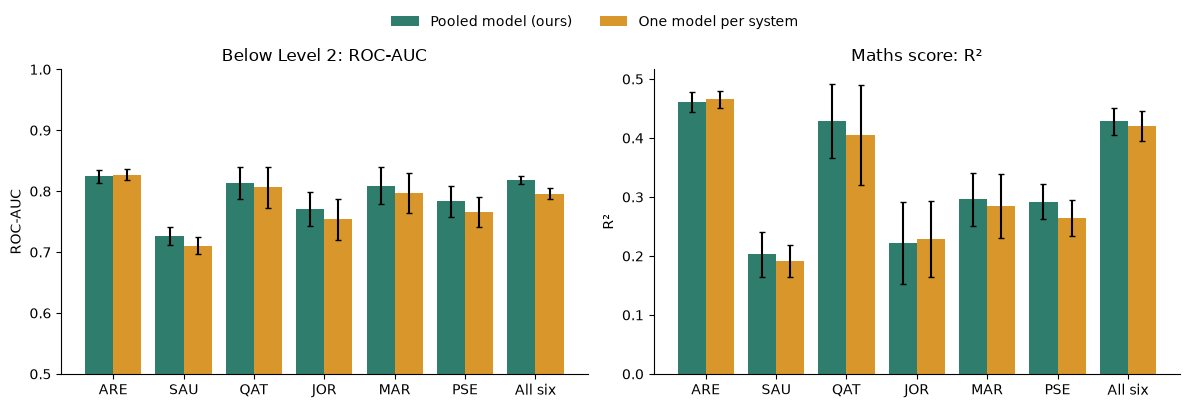

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (task, metric, title) in zip(axes, [("classification", "roc_auc", "Below Level 2: ROC-AUC"),
                                            ("regression", "r2", "Maths score: R²")]):
    bars(ax, [combine(base_scores[task]), combine(own_scores[task])],
         ["Pooled model (ours)", "One model per system"], ["#2F7D6D", "#D9962B"], metric, SYSTEMS + ["pooled"])
    ax.set_title(title)
axes[0].set_ylim(0.5, 1)
axes[0].set_ylabel("ROC-AUC")
axes[1].set_ylabel("R²")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
fig.savefig(FIGS / "ahmed_trial_3_own_model.png", bbox_inches="tight", dpi=150)
plt.show()

**Decision.** We keep one pooled model. A system's own model is ahead in ARE for ROC-AUC and in ARE and JOR for R² (largest gains 0.0026 ROC-AUC, se 0.0025, and 0.0071 R², se 0.0136), and none of these gains is beyond the noise. Everywhere else it is behind, often within the noise too, but clearly in PSE and in the pooled ROC-AUC. ARE, with by far the most students, is the only system where its own model is not behind on either. But both gains are within the noise, so these numbers cannot tell us whether more students per system would help. If the aim is a fairer cut-off inside each system, balancing the class weights per system (tested in `ahmed_country_immigrant.ipynb`) gets it without splitting the data, but section 5 of that notebook shows it also lowers the pooled ROC-AUC (probably with the per-system weights alone, and clearly once country is added as well). So it is a choice between one ranking across all six and a fairer cut-off inside each.

# 6) Trial 4: averaging gradient boosting and the MLP
**Why.** Gradient boosting and the MLP learn in different ways (steps from trees against a smooth function), so some of their errors may cancel. Averaging their predictions is the simplest ensemble, like soft voting.

**What we did.** We refit the MLP with its tuned settings on the same PVs and folds, with the same pipeline as `ahmed_mlp.ipynb`, and average its predictions with the gradient boosting ones from 1.2: probabilities for below Level 2, scores for the maths score. Both classifiers are trained with balanced class weights, so their probabilities are on the same scale. The average and the MLP alone are both paired with gradient boosting alone on each PV and fold.

We did not run stacking, because `StackingClassifier` would need inner folds that keep schools together and pass the sample weights. Eren and Niksarli (2026) also found that stacking added only about 0.004 ROC-AUC over their best single model.

In [16]:
def mlp_fit_predict(task, y, train, test):
    if task == "classification":
        model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                              MLPClassifier(**mlp_best[task], early_stopping=True, random_state=0))
        model.fit(X_mlp[train], y[train],
                  mlpclassifier__sample_weight=w[train] * compute_sample_weight("balanced", y[train]))
        return model.predict_proba(X_mlp[test])[:, 1]
    mlp = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                        MLPRegressor(**mlp_best[task], early_stopping=True, random_state=0))
    model = TransformedTargetRegressor(regressor=mlp, transformer=StandardScaler())
    model.fit(X_mlp[train], y[train], mlpregressor__sample_weight=w[train])
    return model.predict(X_mlp[test])


mlp_scores, avg_scores = {}, {}
for task in TASKS:
    mlp = run(task, PVS, fit=mlp_fit_predict)
    mlp_scores[task] = fold_scores(task, mlp)
    avg_scores[task] = fold_scores(task, {pv: (base[task][pv] + mlp[pv]) / 2 for pv in PVS})

saved_mlp = pd.read_csv(NN / "ahmed_mlp_results.csv")
check = pd.concat([combine(mlp_scores[task]).query("system == 'pooled'").assign(task=task) for task in TASKS])
check = check.merge(saved_mlp[["task", "metric", "score"]], on=["task", "metric"], suffixes=("", "_saved"))
print("largest gap to the saved MLP scores:", (check["score"] - check["score_saved"]).abs().max())
check.round(4)

largest gap to the saved MLP scores: 5.551115123125783e-17


,metric,score,se,system,task,score_saved
0,roc_auc,0.8122,0.0043,pooled,classification,0.8122
1,balanced_acc,0.7297,0.0045,pooled,classification,0.7297
2,rmse,61.6528,0.2783,pooled,regression,61.6528
3,r2,0.4115,0.0108,pooled,regression,0.4115


> **Note:** the refit gives the same pooled scores as `ahmed_mlp_results.csv` (largest gap 6e-17, which is just rounding), so this is the MLP from `ahmed_mlp.ipynb`.

In [17]:
for task in TASKS:
    pooled = "system == 'pooled'"
    keep("ensemble", "gradient boosting", task, combine(base_scores[task]).query(pooled))
    keep("ensemble", "MLP", task, combine(mlp_scores[task]).query(pooled))
    keep("ensemble", "average", task, combine(avg_scores[task]).query(pooled))
    keep("ensemble", "gain of MLP", task, gain(mlp_scores[task], base_scores[task]).query(pooled))
    keep("ensemble", "gain of average", task, gain(avg_scores[task], base_scores[task]).query(pooled))
show("ensemble", ["pooled"])

variant                            gradient boosting              MLP          \
                                               score      se    score      se   
task           metric       system                                              
classification balanced_acc pooled            0.7350  0.0035   0.7297  0.0045   
               roc_auc      pooled            0.8186  0.0036   0.8122  0.0043   
regression     r2           pooled            0.4285  0.0117   0.4115  0.0108   
               rmse         pooled           60.7497  0.3279  61.6528  0.2783   

variant                             average         gain of MLP          \
                                      score      se       score      se   
task           metric       system                                        
classification balanced_acc pooled   0.7354  0.0036     -0.0053  0.0031   
               roc_auc      pooled   0.8194  0.0038     -0.0064  0.0018   
regression     r2           pooled   0.4286  0.0109     -0.0170  0.0037   
               rmse         pooled  60.7493  0.2900     -0.9030  0.1963   

variant                            gain of average          
                                             score      se  
task           metric       system                          
classification balanced_acc pooled          0.0004  0.0019  
               roc_auc      pooled          0.0009  0.0009  
regression     r2           pooled          0.0001  0.0019  
               rmse         pooled          0.0005  0.0972

> **Note:** against gradient boosting alone, the average changes the ROC-AUC by +0.0009 (se 0.0009) and the R² by +0.0001 (se 0.0019), and the MLP alone is behind by 0.0064 ROC-AUC (se 0.0018) and 0.0170 R² (se 0.0037). These se come from the paired gains, so they are smaller than the cautious ones in `ahmed_mlp.ipynb`. With them the MLP's gaps are clear (about 3.5 and 4.6 se), while the average is within the noise of gradient boosting alone.

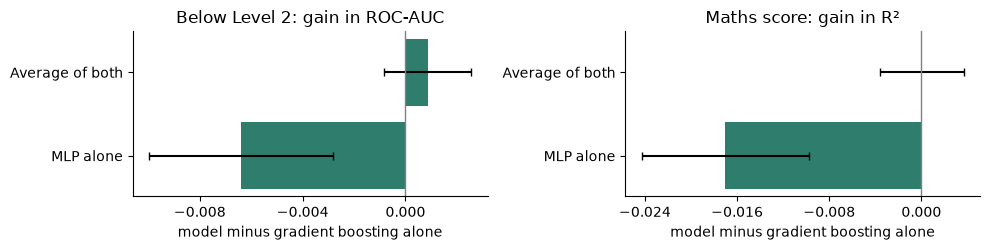

In [18]:
ens = pd.concat(trials)
ens = ens[(ens["trial"] == "ensemble") & ens["variant"].str.startswith("gain of")]
fig, axes = plt.subplots(1, 2, figsize=(10, 2.6))
for ax, (metric, title) in zip(axes, [("roc_auc", "Below Level 2: gain in ROC-AUC"), ("r2", "Maths score: gain in R²")]):
    d = ens[ens["metric"] == metric]
    ax.barh(d["variant"].map({"gain of MLP": "MLP alone", "gain of average": "Average of both"}),
            d["score"], xerr=1.96 * d["se"], color="#2F7D6D", capsize=3)
    ax.axvline(0, color="grey", lw=1)
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.set_title(title)
    ax.set_xlabel("model minus gradient boosting alone")
fig.tight_layout()
fig.savefig(FIGS / "ahmed_trial_4_ensemble.png", bbox_inches="tight", dpi=150)
plt.show()

**Decision.** Not used. Averaging changes the ROC-AUC by +0.0009 (se 0.0009) and the R² by +0.0001 (se 0.0019), both well within 2 se, too small to be worth a second model that needs filling and scaling, and in line with the small gain Eren and Niksarli (2026) saw from stacking.

# 7) Summary
All the trials in one table, saved to `outputs/ahmed_trials.csv` (columns: trial, variant, task, system, metric, score, se, with system `pooled` for all six together). Rows whose variant starts with `gain of` are paired gains over the trial's reference (the school folds in trial 1, the main model otherwise): positive means better, for RMSE lower. Below are the headline gains.

In [19]:
results = pd.concat(trials, ignore_index=True)
results.to_csv(OUT / "ahmed_trials.csv", index=False)
heads = results[results["variant"].str.startswith("gain of") & results["metric"].isin(["roc_auc", "r2"])]
heads.set_index(["trial", "variant", "system", "metric"])[["score", "se"]].unstack("metric").round(4)

score          \
metric                                                      r2 roc_auc   
trial                variant                    system                   
ensemble             gain of MLP                pooled -0.0170 -0.0064   
                     gain of average            pooled  0.0001  0.0009   
leave one system out gain of other five systems ARE    -0.0961 -0.0256   
                                                JOR    -0.0237 -0.0010   
                                                MAR    -0.0452 -0.0257   
                                                PSE    -0.0141 -0.0036   
                                                QAT    -0.0081 -0.0028   
                                                SAU    -0.0230 -0.0032   
one model per system gain of own model          ARE     0.0055  0.0026   
                                                JOR     0.0071 -0.0174   
                                                MAR    -0.0118 -0.0122   
                                                PSE    -0.0279 -0.0175   
                                                QAT    -0.0245 -0.0070   
                                                SAU    -0.0107 -0.0157   
                                                pooled -0.0079 -0.0229   
random split         gain of random folds       ARE     0.0157  0.0035   
                                                JOR     0.0411  0.0072   
                                                MAR     0.0679  0.0159   
                                                PSE     0.0155  0.0043   
                                                QAT     0.0410  0.0080   
                                                SAU     0.0267  0.0085   
                                                pooled  0.0264  0.0065   

                                                            se          
metric                                                      r2 roc_auc  
trial                variant                    system                  
ensemble             gain of MLP                pooled  0.0037  0.0018  
                     gain of average            pooled  0.0019  0.0009  
leave one system out gain of other five systems ARE     0.0125  0.0044  
                                                JOR     0.0051  0.0031  
                                                MAR     0.0108  0.0065  
                                                PSE     0.0040  0.0032  
                                                QAT     0.0052  0.0020  
                                                SAU     0.0076  0.0037  
one model per system gain of own model          ARE     0.0061  0.0025  
                                                JOR     0.0136  0.0092  
                                                MAR     0.0122  0.0095  
                                                PSE     0.0078  0.0048  
                                                QAT     0.0135  0.0060  
                                                SAU     0.0143  0.0069  
                                                pooled  0.0051  0.0032  
random split         gain of random folds       ARE     0.0065  0.0058  
                                                JOR     0.0388  0.0163  
                                                MAR     0.0243  0.0160  
                                                PSE     0.0173  0.0121  
                                                QAT     0.0313  0.0130  
                                                SAU     0.0212  0.0085  
                                                pooled  0.0100  0.0030

| Trial | Question | Result (all 10 PVs) | Decision |
|---|---|---|---|
| 0. Ceiling | How good could it get? | 0.118 of the score variance is PV noise, in line with the Technical Report's reliability. ESCS-alone R² matches the OECD's per system. The oracle reaches R² 0.869 and ROC-AUC 0.970, our model 0.428 and 0.819 | Nothing to change. What is missing is in the predictors, not the model |
| 1. Random split | How much does a random split flatter the numbers? | ROC-AUC 0.0065 (se 0.0030), R² 0.0264 (se 0.0100) higher | Keep school folds, and say which split when comparing with published work |
| 2. Leave one system out | Does the model work in a system it has not seen? | R² lower in 6 of 6 systems (clearly in 5), by up to 0.096 (ARE) | Keep the pooled model, and check it on a new system before using it there |
| 3. One model per system | Is a model per system better than one pooled model? | ROC-AUC lower in 5 of 6 systems (clearly in PSE), and 0.0229 lower pooled (se 0.0032) | Keep one pooled model |
| 4. Average with the MLP | Does soft voting help? | ROC-AUC +0.0009 (se 0.0009), R² +0.0001 (se 0.0019), within the noise | Not used |

- What we keep: gradient boosting on the 17 predictors, one model for all six systems, scored on school folds. A model per system is worse (trial 3: pooled ROC-AUC 0.0229 lower, se 0.0032), and averaging with the MLP adds nothing beyond the noise (trial 4).
- What we drop: both of those. We did not run stacking (section 6).
- For the report's recommendations: our numbers are for schools the model has not seen, and a random split, as in most published PISA studies, would add about 0.007 ROC-AUC (se 0.003, about 2 se, so probably real) and 0.026 R² (se 0.010). The model already gets about half of the R² that the PVs allow, so better predictors matter more than a better model. And it is built for these six systems: in a new one it does worse (R² 0.008 to 0.096 lower, clearly in 5 of the 6), so it should be checked there first.

Next: we take the summary table and the three points in the last bullet to the team, for the results and recommendations sections of the report.